# 03 · Encoder: elección, costo y comportamiento sobre el corpus

Este notebook narra la Fase C. **No recalcula nada**: lee lo que escriben los scripts del contenedor `pipeline`.

```bash
docker compose --profile tools run --rm pipeline python -m scripts.benchmark_encoders
docker compose --profile tools run --rm pipeline python -m scripts.embed_chunks --encoder granite-97m --strategy B --sample sample_10000
docker compose --profile tools run --rm pipeline python -m scripts.encoder_report --encoder granite-97m --strategy B --sample sample_10000
```

- **Justificación y decisiones:** [`reports/embeddings/resumen.md`](../reports/embeddings/resumen.md).
- **Métricas:** solo usan el split `dev` del gold estándar, que todavía está en borrador. Son indicativas, porque `dev` tiene 15 preguntas respondibles.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
EMB = ROOT / 'reports' / 'embeddings'
table = lambda name: pd.read_csv(EMB / 'tables' / f'{name}.csv')
figure = lambda name: display(Image(filename=str(EMB / 'figures' / f'{name}.png')))
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
analysis = json.loads((EMB / 'analisis_encoder.json').read_text(encoding='utf-8'))
run = json.loads((EMB / 'runs' / 'granite-97m_B_sample_10000.json').read_text(encoding='utf-8'))
print('Encoder:', run['settings']['model'], '| revisión', run['settings']['revision'][:12])
print('Chunks vectorizados:', run['chunks']['n'], '| dimensión', run['dimension'], '| tiempo', run['seconds'], 's |', run['chunks_per_second'], 'chunks/s')
print('Norma de los vectores (media, mínima):', run['norm']['mean'], run['norm']['min'])
print('Tokens del encoder por chunk (p50, p95, máx):', run['n_tokens'], '| tope', run['max_tokens'])

Encoder: ibm-granite/granite-embedding-97m-multilingual-r2 | revisión 835ad14087e1
Chunks vectorizados: 37919 | dimensión 384 | tiempo 2043.9 s | 18.55 chunks/s
Norma de los vectores (media, mínima): 1.0 0.9999998807907104
Tokens del encoder por chunk (p50, p95, máx): {'p50': 198.0, 'p95': 250.0, 'max': 511} | tope 32768


## 1. Costo en CPU: por qué un encoder pequeño

Todo corre en CPU, dentro de Docker, con 10 núcleos y 8 GB de RAM compartidos con Milvus y Ollama. Los tres candidatos se midieron en el mismo contenedor, con los mismos 256 chunks y el mismo tamaño de lote.

In [2]:
table('costo_encoders')

,profile,model,revision,parameters_m,max_seq_length,rss_before_load_mb,chunks,seconds,chunks_per_second,dimension,peak_rss_mb,hours_per_100k_chunks,mb_per_100k_vectors
0,e5-small,intfloat/multilingual-e5-small,614241f622f53c4eeff9890bdc4f31cfecc418b3,117.700,512,614,256,7.830,32.680,384,1505,0.850,153.600
1,granite-97m,ibm-granite/granite-embedding-97m-multilingual-r2,835ad14087e140460703cf0fae09f97d469d65c2,97.400,32768,614,256,13.140,19.480,384,1862,1.430,153.600
2,qwen3-0.6b,Qwen/Qwen3-Embedding-0.6B,97b0c614be4d77ee51c0cef4e5f07c00f9eb65b3,595.800,32768,614,256,329.810,0.780,1024,6978,35.610,409.600


- **Qwen3-Embedding-0.6B** tiene el mejor puntaje publicado, pero aquí procesa menos de un chunk por segundo. Vectorizar la muestra de 10.000 tomaría unas 13 horas y el corpus completo, cientos.
- **granite-embedding-97m-multilingual-r2** cuesta del orden de e5-small, con la misma dimensión (384), y su puntaje publicado de recuperación multilingüe es claramente mejor.

## 2. Recuperación en dev según el formato de la consulta

,group,n,recall@1,recall@5,recall@10,recall@20,hit@1,hit@5,hit@10,hit@20,mrr,ndcg@10,evidence@5,evidence@10,variant
0,total,15,0.483,0.800,0.933,0.933,0.667,0.867,0.933,0.933,0.734,0.764,0.733,0.867,perfil
1,total,15,0.483,0.800,0.933,1.000,0.667,0.867,0.933,1.000,0.746,0.765,0.800,0.867,prefijo_e5
2,total,15,0.483,0.800,0.933,0.933,0.667,0.867,0.933,0.933,0.734,0.764,0.733,0.867,sin_filtro_fecha
3,total,15,0.383,0.867,0.867,0.933,0.533,0.867,0.867,0.933,0.687,0.728,0.800,0.867,parafrasis
4,total,15,0.317,0.650,0.833,1.000,0.467,0.733,0.867,1.000,0.581,0.622,0.600,0.867,traduccion


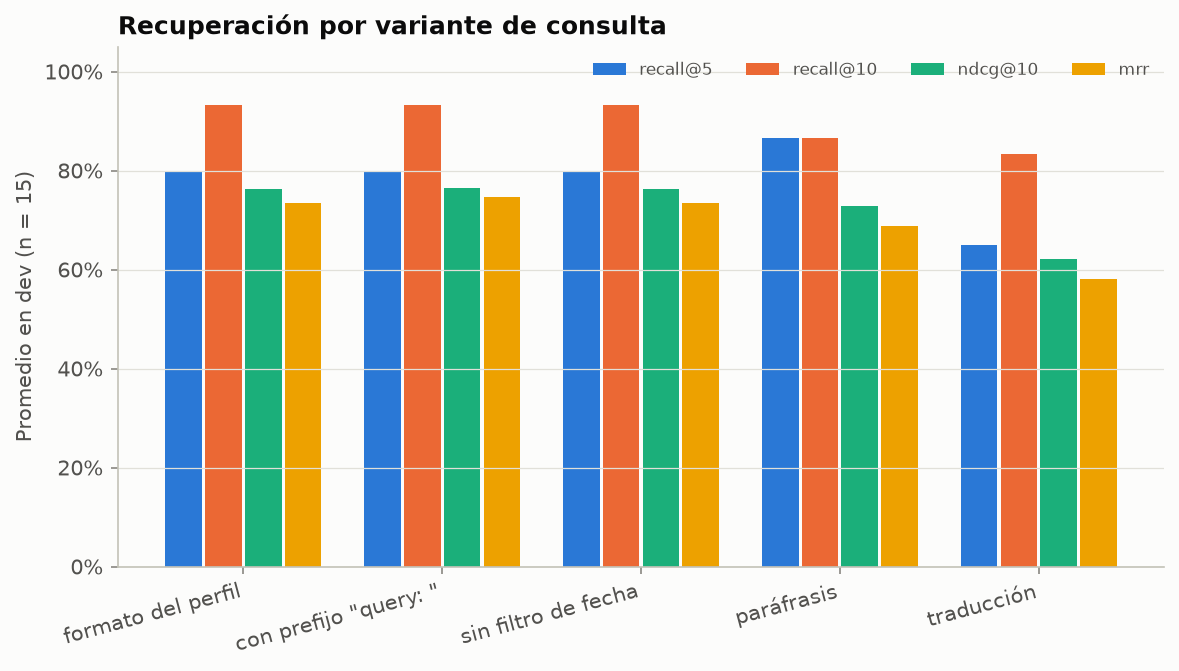

In [3]:
display(table('metricas_variantes'))
figure('variantes_consulta')

- **Prefijo `query: `:** granite no usa prefijos ni instrucciones. Agregarle el prefijo de E5 mide qué tan sensible es al formato de la consulta.
- **Filtro de fecha:** solo cambia la pregunta con `ventana_fecha` (Q51).
- **Paráfrasis y traducción:** muestran si el resultado depende de la redacción exacta o del idioma de la pregunta.

## 3. Idiomas: preguntas en español con evidencia en inglés o húngaro

,group,n,recall@1,recall@5,recall@10,recall@20,hit@1,hit@5,hit@10,hit@20,mrr,ndcg@10,evidence@5,evidence@10,consulta
0,en,4,0.312,1.000,1.000,1.000,0.750,1.000,1.000,1.000,0.800,0.847,0.750,1.000,original
1,es,10,0.600,0.700,0.900,0.900,0.700,0.800,0.900,0.900,0.748,0.757,0.800,0.900,original
2,hu,1,0.000,1.000,1.000,1.000,0.000,1.000,1.000,1.000,0.333,0.500,0.000,0.000,original
3,total,15,0.483,0.800,0.933,0.933,0.667,0.867,0.933,0.933,0.734,0.764,0.733,0.867,original
4,en,4,0.312,0.938,1.000,1.000,0.750,1.000,1.000,1.000,0.800,0.828,0.750,1.000,traduccion
5,es,10,0.350,0.600,0.850,1.000,0.400,0.700,0.900,1.000,0.546,0.602,0.600,0.900,traduccion
6,hu,1,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.067,0.000,0.000,0.000,traduccion
7,total,15,0.317,0.650,0.833,1.000,0.467,0.733,0.867,1.000,0.581,0.622,0.600,0.867,traduccion


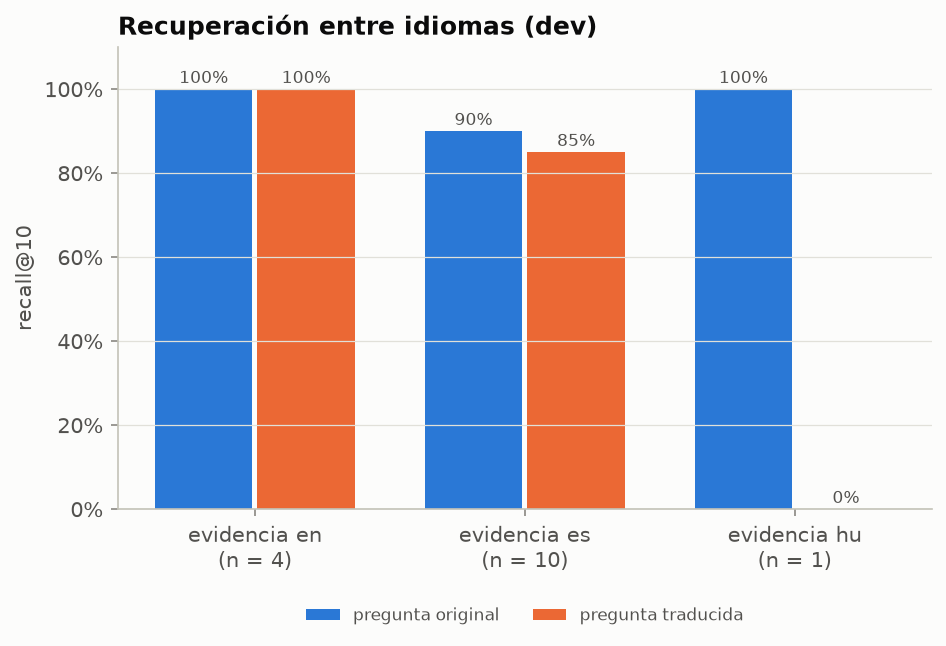

,id,variant,cosine_query,jaccard_top10
0,Q01,parafrasis,0.963,0.538
1,Q02,parafrasis,0.966,0.538
2,Q04,parafrasis,0.983,0.667
3,Q06,parafrasis,0.972,0.429
4,Q09,parafrasis,0.922,0.538
5,Q11,parafrasis,0.962,0.429
6,Q12,parafrasis,0.952,0.333
7,Q17,parafrasis,0.980,0.333
8,Q19,parafrasis,0.989,0.667
9,Q25,parafrasis,0.965,0.429


In [4]:
display(table('metricas_por_idioma'))
figure('idiomas')
table('estabilidad_consultas')

## 4. Dimensión del vector y normalización

,group,n,recall@1,recall@5,recall@10,recall@20,hit@1,hit@5,hit@10,hit@20,mrr,ndcg@10,evidence@5,evidence@10,dimension,renormalized,mb_per_100k_chunks
0,total,15,0.483,0.800,0.933,0.933,0.667,0.867,0.933,0.933,0.734,0.764,0.733,0.867,384,True,153.600
1,total,15,0.483,0.700,0.867,0.933,0.667,0.733,0.867,0.933,0.713,0.738,0.733,0.800,256,True,102.400
2,total,15,0.483,0.800,0.867,0.867,0.667,0.800,0.867,0.867,0.713,0.751,0.800,0.867,256,False,102.400
3,total,15,0.450,0.700,0.733,0.867,0.600,0.733,0.733,0.867,0.665,0.680,0.733,0.733,128,True,51.200
4,total,15,0.417,0.650,0.800,0.800,0.600,0.667,0.800,0.800,0.633,0.667,0.667,0.800,128,False,51.200


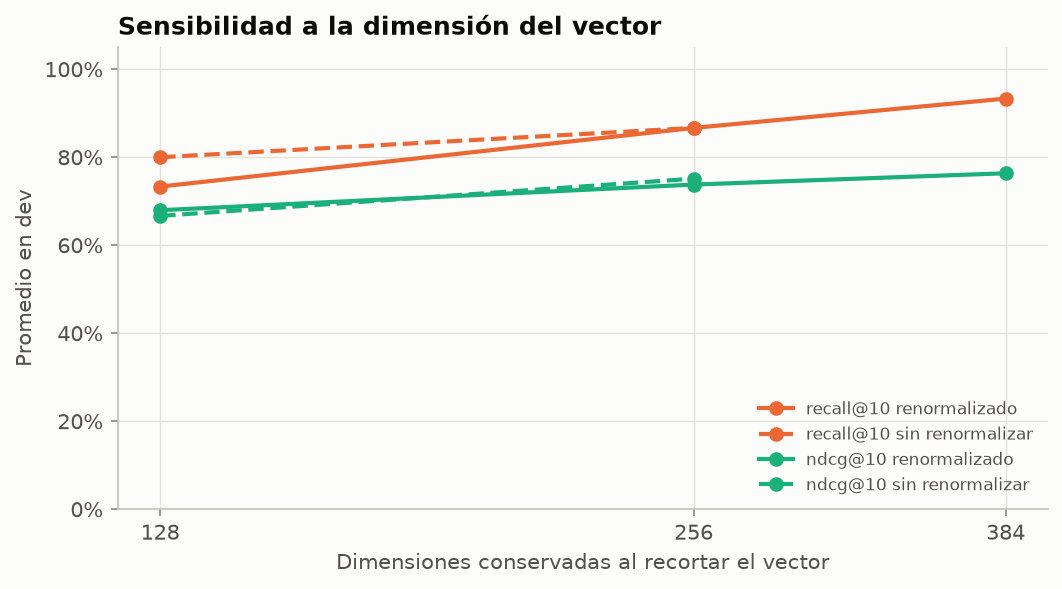

In [5]:
display(table('matryoshka'))
figure('matryoshka')

granite-97m no se entrenó con Matryoshka. Recortar sus 384 dimensiones muestra cuánto se pierde al hacerlo.

Los vectores salen normalizados (norma 1), así que la similitud coseno y el producto interno dan el mismo orden. Sin renormalizar después de recortar, deja de cumplirse.

## 5. Vecinos de ejemplo (solo identificadores y metadatos)

In [6]:
nb = table('vecinos_ejemplo')
nb[nb['id'].isin(['Q04', 'Q12', 'Q49', 'Q51'])]

,id,idioma_pregunta,rank,document_id,collection_name,language_detected,created_at,score,grado
10,Q04,es,1,url_crawls:crawl_uq_77990dd72a7083a49dbe26d8_m...,url_crawls,es,2020-12-11,0.890,0
11,Q04,es,2,url_crawls:crawl_uq_6de0ca9af388776b0a04d754_m...,url_crawls,es,2026-07-02,0.864,0
12,Q04,es,3,url_crawls:crawl_uq_36efa17eee34fdd4fcca1c89_m...,url_crawls,hu,2026-05-16,0.855,2
13,Q04,es,4,url_crawls:crawl_uq_077e68f8eb23040f620ce963_m...,url_crawls,en,2025-03-04,0.852,0
14,Q04,es,5,url_crawls:crawl_uq_2a9729cdbca7d52e85ea2229_m...,url_crawls,en,2024-04-22,0.850,0
30,Q12,es,1,url_crawls:crawl_uq_4b5c014b146c1936ac1e0575_m...,url_crawls,en,2025-10-16,0.868,0
31,Q12,es,2,url_crawls:crawl_uq_bb7ed4eb62044db04f5f53ad_c...,url_crawls,es,2023-05-19,0.857,0
32,Q12,es,3,url_crawls:crawl_uq_813879be4e5ae13d0e6597df_m...,url_crawls,en,2024-08-12,0.855,0
33,Q12,es,4,url_crawls:crawl_uq_71d2c2e39bb9a6741a95d65e_m...,url_crawls,en,2023-03-23,0.849,0
34,Q12,es,5,bluesky_posts:bluesky_3miy3ydxyks2o,bluesky_posts,en,2026-04-08,0.848,2


`grado` es la relevancia anotada en el gold: 2 = responde; 0 = no anotado como relevante. Por la regla de datos del proyecto, se muestran identificadores y metadatos, nunca el texto de los documentos.